<a href="https://colab.research.google.com/github/VenusStar84/dlczf/blob/main/PESCAzebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepLabCut for your standard (single animal) projects!

Some useful links:

- [DeepLabCut's GitHub: github.com/DeepLabCut/DeepLabCut](https://github.com/DeepLabCut/DeepLabCut)
- [DeepLabCut's Documentation: User Guide for Single Animal projects](https://deeplabcut.github.io/DeepLabCut/docs/standardDeepLabCut_UserGuide.html)


This notebook illustrates how to use the cloud to:
- create a training set
- train a network
- evaluate a network
- create simple quality check plots
- analyze novel videos!

### This notebook assumes you already have a project folder with labeled data!

This notebook demonstrates the necessary steps to use DeepLabCut for your own project.

This shows the most simple code to do so, but many of the functions have additional features, so please check out the [documentation](https://deeplabcut.github.io/DeepLabCut/docs/standardDeepLabCut_UserGuide.html) & the protocol paper!

> Nath, T., Mathis, A., Chen, A. C., Patel, A., Bethge, M., & Mathis, M. W. (2019).  
> **Using DeepLabCut for 3D markerless pose estimation across species and behaviors.**  
> *Nature Protocols, 14*(7), 2152–2176.  
> https://doi.org/10.1038/s41596-019-0176-0

Pre-print: https://www.biorxiv.org/content/biorxiv/early/2018/11/24/476531.full.pdf


## First, go to "Runtime" ->"change runtime type"->select "Python3", and then select "GPU"

As the COLAB environments were updated to CUDA 12.X and Python 3.11, we need to install DeepLabCut and TensorFlow in a distinct way to get TensorFlow to connect to the GPU.

In [8]:
# this will take a couple of minutes to install all the dependencies!
!pip install --pre deeplabcut

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 18.6 MB/s  0:00:00
  Attempting uninstall: filelock
    Found existing installation: filelock 4.2.4
    Uninstalling filelock-4.2.4:
      Successfully uninstalled filelock-4.2.4
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [deeplabcut]


**(Be sure to click "RESTART RUNTIME" if it is displayed above before moving on !)** You will see this button at the output of the cells above ^.

In [9]:
import deeplabcut

## Link your Google Drive (with your labeled data, or the demo data):

### First, place your project folder into you google drive! "i.e. move the folder named "Project-YourName-TheDate" into google drive.

In [10]:
# Now, let's link to your GoogleDrive. Run this cell and follow the authorization instructions:
# (We recommend putting a copy of the github repo in your google drive if you are using the demo "examples")

from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


YOU WILL NEED TO EDIT THE PROJECT PATH **in the config.yaml file** TO BE SET TO YOUR GOOGLE DRIVE LINK!

Typically, this will be: `/content/drive/My Drive/yourProjectFolderName`


In [11]:
project_folder_name = "zebraVid-venus-2026-10-26"
video_type = "mp4"

videofile_path = [f"/content/drive/MyDrive/{project_folder_name}/videos/"]
destfolder = f"/content/drive/MyDrive/{project_folder_name}/labeled-videos"
path_config_file = f"/content/drive/MyDrive/{project_folder_name}/config.yaml"
print(path_config_file)

/content/drive/MyDrive/zebraVid-venus-2026-10-26/config.yaml


## Create a training dataset:

### You must do this step inside of Colab

After running this script the training dataset is created and saved in the project directory under the subdirectory **'training-datasets'**

This function also creates new subdirectories under **dlc-models-pytorch** and appends the project config.yaml file with the correct path to the training and testing pose configuration file. These files hold the parameters for training the network. Such an example file is provided with the toolbox and named as **pytorch_config.yaml**.

Now it is the time to start training the network!

In [12]:
# There are many more functions you can set here, including which network to use!
# Check the docstring for `create_training_dataset` for all options you can use!

deeplabcut.create_training_dataset(path_config_file, net_type="resnet_101", engine=deeplabcut.Engine.PYTORCH)

/content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-data/C:\Users\click\Desktop\zebraVid-venus-2026-10-26\videos\VID_20261020_123228/CollectedData_venus.h5  not found (perhaps not annotated).
Annotation data was not found by splitting video paths (from config['video_sets']). An alternative route is taken...
The following folders were found: [PosixPath('/content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-data/VID_20261020_123228_labeled'), PosixPath('/content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-data/VID_20261020_123228')]
/content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-data/VID_20261020_123228_labeled/CollectedData_venus.h5  not found (perhaps not annotated)


[(0.95,
  3,
  (array([133, 109,  59,  80,   7, 104, 140,  95, 118,  84,  33,  44,  54,
           24,  37, 132, 111,  73,  16,  45,  40,   8,  85,  22,  62,  94,
           90,  26,  43, 134,  27,  97,  96,  69,  18, 105, 136,  61,  51,
            2, 146,  10,  56, 113, 143, 116,  66,  78,  71, 131, 120,  89,
          145, 100,  50, 126,  60,  30,  63,  91,  83,  86, 123,  98, 122,
           48,  13, 108,  92,  20,  15,  52,   3, 127,  76,   6,  68, 106,
           93,  12, 124, 147, 101, 125,  46,  11, 107, 112,  41, 114,   1,
          110, 138,  42,   4, 128,  17,  38,   5,  53, 142, 102,   0,  34,
           28,  55,  75,  35,  23,  74,  31, 121,  57, 130,  65,  32, 137,
           14, 119,  19,  29, 129,  49, 135,  99,  82,  64, 148,  79, 115,
          144,  72,  77,  25,  81, 139, 141,  39,  58,  88,  70]),
   array([ 87,  36,  21,   9, 103,  67, 117,  47])))]

## Start training:
This function trains the network for a specific shuffle of the training dataset.

In [13]:
# Let's also change the display and save_epochs just in case Colab takes away
# the GPU... If that happens, you can reload from a saved point using the
# `snapshot_path` argument to `deeplabcut.train_network`:
#   deeplabcut.train_network(..., snapshot_path="/content/.../snapshot-050.pt")

# Typically, you want to train to ~200 epochs. We set the batch size to 8 to
# utilize the GPU's capabilities.

# More info and there are more things you can set:
#   https://deeplabcut.github.io/DeepLabCut/docs/standardDeepLabCut_UserGuide.html#g-train-the-network

deeplabcut.train_network(
    path_config_file,
    shuffle=2,
    save_epochs=5,
    epochs=200,
    batch_size=8,
)

# This will run until you stop it (CTRL+C), or hit "STOP" icon, or when it hits the end.

Training with configuration:
config_version: 0
model: backbone={'type': 'ResNet', 'model_name': 'resnet101', 'output_stride': 16, 'freeze_bn_stats': False, 'freeze_bn_weights': False} heads={'bodypart': {'type': 'HeatmapHead', 'weight_init': 'normal', 'predictor': {'type': 'HeatmapPredictor', 'apply_sigmoid': False, 'clip_scores': True, 'location_refinement': True, 'locref_std': 7.2801}, 'target_generator': {'type': 'HeatmapGaussianGenerator', 'num_heatmaps': 2, 'pos_dist_thresh': 17, 'heatmap_mode': 'KEYPOINT', 'gradient_masking': False, 'generate_locref': True, 'locref_std': 7.2801}, 'criterion': {'heatmap': {'type': 'WeightedMSECriterion', 'weight': 1.0}, 'locref': {'type': 'WeightedHuberCriterion', 'weight': 0.05}}, 'heatmap_config': {'channels': [2048, 2], 'kernel_size': [3], 'strides': [2]}, 'locref_config': {'channels': [2048, 4], 'kernel_size': [3], 'strides': [2]}}} backbone_output_channels=2048 neck=None pose_model=None
net_type: NetType.RESNET_101
method: MethodType.BOTTOM_U

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

[timm/resnet101.a1h_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
Loading existing CSV data from /content/drive/MyDrive/zebraVid-venus-2026-10-26/dlc-models-pytorch/iteration-0/zebraVidOct26-trainset95shuffle2/train/learning_stats.csv
Data Transforms:
  Training:   Compose([
  Affine(always_apply=False, p=0.5, interpolation=1, mask_interpolation=0, cval=0, mode=0, scale={'x': (0.5, 1.25), 'y': (0.5, 1.25)}, translate_percent=None, translate_px={'x': (0, 0), 'y': (0, 0)}, rotate=(-30, 30), fit_output=False, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, cval_mask=0, keep_ratio=True, rotate_method='largest_box'),
  PadIfNeeded(always_apply=True, p=1.0, min_height=448, min_width=448, pad_height_divisor=None, pad_width_divisor=None, position=PositionType.CENTER, border_mode=0, value=None, mask_value=None),
  KeypointAwareCrop(always_apply=True, p=1.0, width=448, height=448, max_shift=0.1, crop_sampling='hybrid'),
  MotionBl

Note, that **when you hit "STOP" you will get a `KeyboardInterrupt` "error"! No worries! :)**

## Start evaluating:
This function evaluates a trained model for a specific shuffle/shuffles at a particular state or all the states on the data set (images)
and stores the results as .csv file in a subdirectory under **evaluation-results-pytorch**

In [14]:
deeplabcut.evaluate_network(path_config_file, Shuffles=[2], plotting=True)

# Here you want to see a low pixel error! Of course, it can only be as
# good as the labeler, so be sure your labels are good!

Evaluation scorer: DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190


100%|██████████| 8/8 [00:01<00:00,  6.15it/s]


Evaluation results file: DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190-results.csv
Evaluation results for DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190-results.csv (pcutoff: 0.6):
train rmse             1.01
train rmse_pcutoff     1.01
train mAP             80.45
train mAR             88.33
test rmse              2.38
test rmse_pcutoff      2.38
test mAP              52.90
test mAR              60.00
Name: (0.95, 2, 190, -1, 0.6), dtype: float64


## There is an optional refinement step you can do outside of Colab:
- if your pixel errors are not low enough, please check out the protocol guide on how to refine your network!
- You will need to adjust the labels **outside of Colab!** We recommend coming back to train and analyze videos...
- Please see the repo and protocol instructions on how to refine your data!

## Start Analyzing videos:
This function analyzes the new video. The user can choose the best model from the evaluation results and specify the correct snapshot index for the variable **snapshotindex** in the **config.yaml** file. Otherwise, by default the most recent snapshot is used to analyse the video.

The results are stored in hd5 file in the same directory where the video resides.

In [17]:
deeplabcut.analyze_videos(
    path_config_file,
    videofile_path,
    videotype=video_type,
    shuffle=2,
    save_as_csv=True,
    destfolder=destfolder,
)

Analyzing videos with /content/drive/MyDrive/zebraVid-venus-2026-10-26/dlc-models-pytorch/iteration-0/zebraVidOct26-trainset95shuffle2/train/snapshot-best-190.pt
Using scorer: DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190
Video /content/drive/MyDrive/zebraVid-venus-2026-10-26/videos/VID_20261020_123228.mp4 already analyzed at /content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-videos/VID_20261020_123228DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190_full.pickle!
No .h5 files were created during video analysis. Please check your code and ensure that the video inference and output generation are correct.



'DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190'



A próxima cédula basicamente converte arquivos .h5 para CSV**

In [19]:
import glob
import pandas as pd

for f in glob.glob(destfolder + "/*.h5"):
    df = pd.read_hdf(f)
    df.to_csv(f.replace(".h5", ".csv"))
    print("convertido:", f)

convertido: /content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-videos/VID_20261020_123228DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190.h5
convertido: /content/drive/MyDrive/zebraVid-venus-2026-10-26/labeled-videos/VID_20261020_123458DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190.h5


In [20]:
import pandas as pd

f = destfolder + "/VID_20261020_123458DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190.csv"
df = pd.read_csv(f, header=[1, 2], index_col=0)
print(df.columns.tolist())
print(len(df), "frames")

[('cabeca', 'x'), ('cabeca', 'y'), ('cabeca', 'likelihood'), ('rabo', 'x'), ('rabo', 'y'), ('rabo', 'likelihood')]
344 frames


abriu: True
frames: 344.0
fps: 29.843581461120927 | tamanho: 1080 x 1920


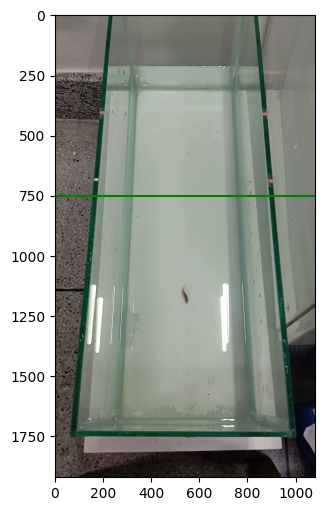

In [31]:
import os, cv2

import cv2
import matplotlib.pyplot as plt

video = "/content/drive/MyDrive/zebraVid-venus-2026-10-26/videos_novos/VID_20261020_123458.mp4"
cap = cv2.VideoCapture(video)
print("abriu:", cap.isOpened())
print("frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
print("fps:", fps, "| tamanho:", largura, "x", altura)

ok, frame = cap.read()
cap.release()

linha_y = 750 # ajuste depois
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axhline(linha_y, color="green")
plt.show()

In [30]:
import pandas as pd

f = destfolder + "/VID_20261020_123458DLC_Resnet101_zebraVidOct26shuffle2_snapshot_best-190.csv"
df = pd.read_csv(f, header=[1, 2], index_col=0)

fps = 29.84
linha_y = 750      # y = 0 é o topo; menor que 750 = cima
pcutoff = 0.6
ponto = "cabeca"   # ponto que representa o peixe (pode trocar por "rabo")

y = df[(ponto, "y")]
conf = df[(ponto, "likelihood")]

ok = conf >= pcutoff
cima = (y < linha_y) & ok
embaixo = (y >= linha_y) & ok

print(f"Cima:    {cima.sum() / fps:.1f} s")
print(f"Embaixo: {embaixo.sum() / fps:.1f} s")
print(f"Frames descartados (baixa confiança): {(~ok).sum()} de {len(df)}")

Cima:    1.3 s
Embaixo: 9.6 s
Frames descartados (baixa confiança): 18 de 344


## Plot the trajectories of the analyzed videos:
This function plots the trajectories of all the body parts across the entire video. Each body part is identified by a unique color.

/tmp/ipykernel_821/2430615552.py:1: DLCDeprecationWarning: Parameter 'videotype' of plot_trajectories is deprecated since 3.0.0; use 'video_extensions' instead.
  deeplabcut.plot_trajectories(


Loading  /content/drive/MyDrive/zebraVid-venus-2026-10-26/videos/VID_20261020_123228.mp4 and data.
Plots created! Please check the directory "plot-poses" within the video directory


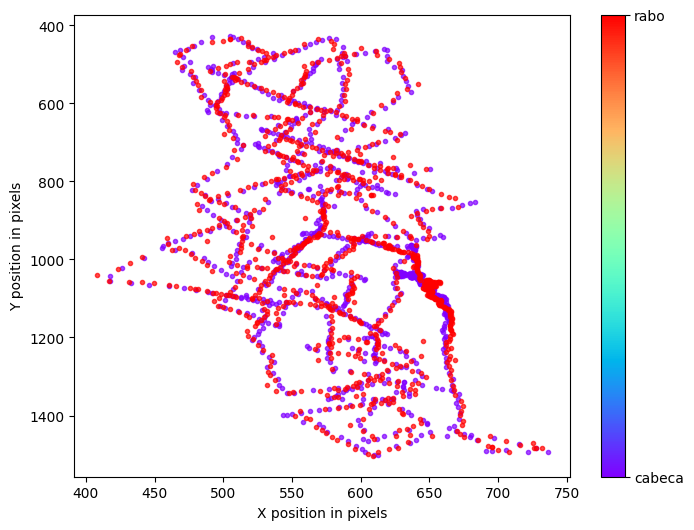

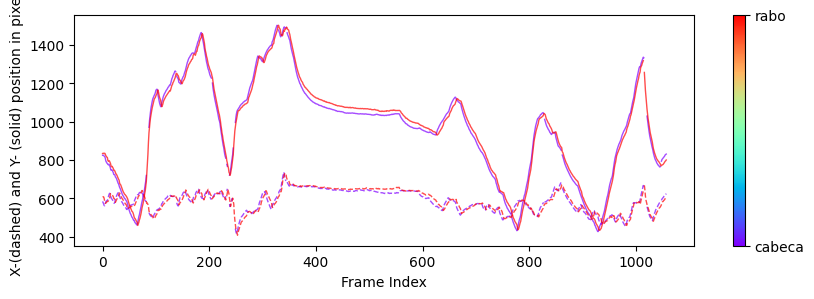

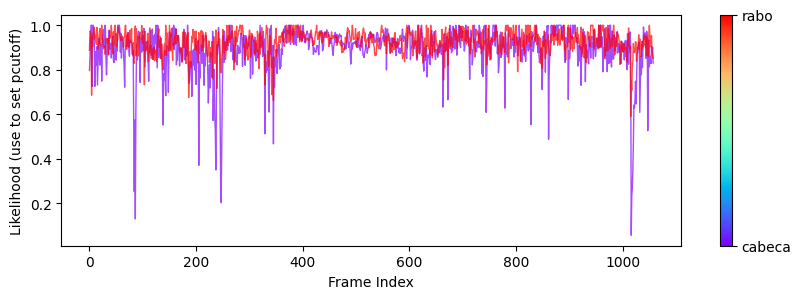

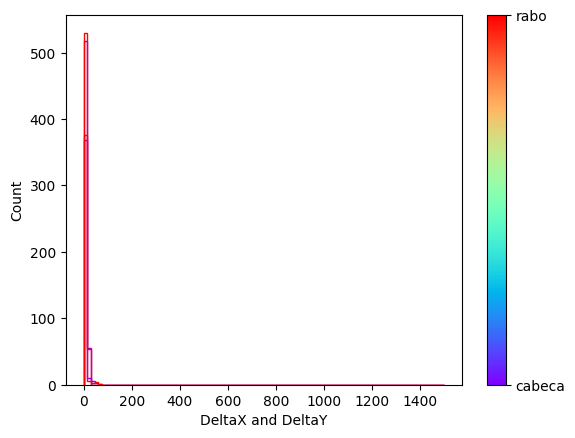

In [16]:
deeplabcut.plot_trajectories(
    path_config_file,
    videofile_path,
    videotype=video_type,
    shuffle=2,
    destfolder=destfolder,
)

Now you can look at the plot-poses file and check the "plot-likelihood.png" might want to change the "p-cutoff" in the config.yaml file so that you have only high confidnece points plotted in the video. i.e. ~0.8 or 0.9. The current default is 0.4.

## Create labeled video:
This function is for visualization purpose and can be used to create a video in .mp4 format with labels predicted by the network. This video is saved in the same directory where the original video resides.

In [ ]:
deeplabcut.create_labeled_video(
    path_config_file,
    videofile_path,
    videotype=video_type,
    shuffle=2,
    destfolder=destfolder,
)

/tmp/ipykernel_4532/501131009.py:1: DLCDeprecationWarning: Parameter 'videotype' of create_labeled_video is deprecated since 3.0.0; use 'video_extensions' instead.
  deeplabcut.create_labeled_video(


Starting to process video: /content/drive/MyDrive/canetaVoadora-venus-2026-10-19/videos/IMG_1689.mov
Loading /content/drive/MyDrive/canetaVoadora-venus-2026-10-19/videos/IMG_1689.mov and data.
Duration of video [s]: 41.67, recorded with 30.0 fps!
Overall # of frames: 1250 with cropped frame dimensions: 1080 1920
Generating frames and creating video.


100%|██████████| 1250/1250 [02:39<00:00,  7.84it/s]


[True]